# Modularity on the Karate Club Graph — Recursive Spectral Bisection


**Goal.** Starting from only the *structure* of Zachary's Karate Club network (34 members, 78 friendships), recover the groups that the club actually split into, using the **spectral modularity method** of Newman (2006), implemented from scratch with `numpy` + `networkx`.



In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque
import os

os.makedirs("assets", exist_ok=True)
plt.rcParams["figure.dpi"] = 110

## 1. Load the data and build the matrices

* `A` — adjacency matrix: `A[i,j] = 1` if members `i` and `j` are friends.
* `k` — degree vector: `k[i] = Σ_j A[i,j]`.
* `m` — number of edges, so `Σ_i k[i] = 2m`.
* `B = A − k kᵀ / (2m)` — the **modularity matrix**. Entry `B[i,j]` = *(edge actually present)* − *(edge expected under the degree-preserving random null model)*. Positive means "more connected than chance".

> **Why rebuild the graph?** In recent NetworkX versions `karate_club_graph()` stores a `weight` on each edge. The handout treats the graph as *unweighted* (`A ∈ {0,1}`), so we copy only the edges and ask for `weight=None`. Otherwise the identity `B·1 = 0` silently fails.

In [2]:
# Copy the structure only (drop edge weights) and keep the real-world 'club' label as ground truth
G0 = nx.karate_club_graph()
G = nx.Graph()
G.add_nodes_from(G0.nodes())
G.add_edges_from(G0.edges())
for i, club in G0.nodes(data="club"):
    G.nodes[i]["club"] = club              # 'Mr. Hi' or 'Officer' (the administrator's side)

nodes = sorted(G.nodes())                   # 0..33  (NetworkX numbers the members from 0)
n, m = G.number_of_nodes(), G.number_of_edges()

A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # n x n, entries 0/1
k = A.sum(axis=1)                                       # degree vector
B = A - np.outer(k, k) / (2 * m)                        # modularity matrix

print(f"n = {n} nodes, m = {m} edges, sum of degrees = {int(k.sum())} (= 2m = {2*m})")

n = 34 nodes, m = 78 edges, sum of degrees = 156 (= 2m = 156)


### Sanity checks of the theory (Proposition 1, Proposition 2, Corollary 1)
We verify numerically what the handout proves:
* **B is symmetric** (Prop. 1).
* **`B·1 = 0`**: every row of `B` sums to zero, so the all-ones vector is an eigenvector with eigenvalue 0 (Prop. 2).
* **Trivial partition** (everyone in one group) has `Q = 0` (Cor. 1).

In [3]:
ones = np.ones(n)
print("B symmetric           :", np.allclose(B, B.T))
print("B @ 1 == 0            :", np.allclose(B @ ones, 0))
print("Q(trivial)=1ᵀB1/(4m)  :", round(float(ones @ B @ ones) / (4 * m), 12))
print("Eigenvalues are real  :", np.isrealobj(np.linalg.eigvalsh(B)))
print("Largest eigenvalue of B:", round(float(np.linalg.eigvalsh(B)[-1]), 4))

B symmetric           : True
B @ 1 == 0            : True
Q(trivial)=1ᵀB1/(4m)  : 0.0
Eigenvalues are real  : True
Largest eigenvalue of B: 4.9771


## 2. The modularity score

For a two-way split `s ∈ {−1,+1}ⁿ` the handout defines `Q = (1/4m) sᵀ B s`.

For a split into **any number of groups** the equivalent (and more general) form is

$$Q = \frac{1}{2m}\sum_{i,j} B_{ij}\,\delta(c_i, c_j)$$

where `c_i` is the community label of node `i` and `δ` is 1 when both nodes share a community. We add up `B[i,j]` over pairs in the *same* community. (Because `B·1 = 0`, for two groups this reduces exactly to `sᵀBs/4m` — we verify that below.)

We use this function to track `Q` after every split.

In [4]:
def modularity_from_labels(B, labels, m):
    """Q = (1/2m) * sum of B[i,j] over all pairs (i,j) in the same community."""
    labels = np.asarray(labels)
    same = labels[:, None] == labels[None, :]       # n x n boolean: True where i and j share a community
    return round(float(B[same].sum() / (2 * m)), 12) + 0.0   # rounding kills float noise like -1e-17 (would print as -0.0)

# Ground truth from Zachary: who followed Mr. Hi vs. the Officer (administrator)
truth = np.array([0 if G.nodes[i]["club"] == "Mr. Hi" else 1 for i in nodes])
print("Q of the real-world split :", round(modularity_from_labels(B, truth, m), 4))

# Check: for two groups, the general formula equals the handout's (1/4m) sᵀ B s
s_truth = np.where(truth == 0, 1, -1)
print("(1/4m) sᵀ B s            :", round(float(s_truth @ B @ s_truth) / (4 * m), 4))

Q of the real-world split : 0.3582
(1/4m) sᵀ B s            : 0.3582


## 3. Spectral bipartition (one split)

Maximising `sᵀBs` over `s ∈ {−1,+1}ⁿ` is a search over `2ⁿ` vectors — infeasible. **Relax** it: allow any real `s` with `‖s‖₂ = 1`. By **Rayleigh–Ritz** (Theorem 2), the maximiser is the eigenvector `u₁` of the *largest* eigenvalue `λ₁`.

Then round back: `sᵢ = +1` if `(u₁)ᵢ > 0`, else `−1`.

Implementation notes:
* `np.linalg.eigh` is for **symmetric** matrices; it returns eigenvalues in **ascending** order, so the leading pair is the **last** one.
* An eigenvector's overall sign is arbitrary (`u` and `−u` are both eigenvectors) — this only swaps which group is called "+", never the partition itself.
* **Restricted matrix** `B^(C)`: for a group `C` we take the sub-block `B[C, C]` (rows and columns of nodes in `C`), exactly as in Section 3.3 of the handout.
* Stop rule: if `λ₁ ≤ 0` (we use a tiny tolerance `1e-8` to absorb floating-point error) the group is indivisible. We also stop if rounding puts *everyone* on one side (nothing to split).

In [5]:
def leading_eigenpair(M):
    """Largest eigenvalue and its (unit-norm) eigenvector of a real symmetric matrix."""
    vals, vecs = np.linalg.eigh(M)       # ascending order
    return float(vals[-1]), vecs[:, -1]

def try_split(idx, B, use_correction=False, tol=1e-8):
    """
    Try to split the group of nodes `idx` in two.
    Returns ((group_plus, group_minus), lambda1)  or  (None, lambda1) if indivisible.

    use_correction=False -> exactly the handout: eigendecompose the plain block B[C, C].
    use_correction=True  -> Newman's 'generalised' matrix (extension, see Section 7).
    """
    idx = np.asarray(idx)
    B_C = B[np.ix_(idx, idx)].copy()                  # restricted modularity matrix B^(C)
    if use_correction:
        B_C = B_C - np.diag(B_C.sum(axis=1))
    lam, u = leading_eigenpair(B_C)
    if lam <= tol:                                    # stopping rule (Theorem 3)
        return None, lam
    s = np.where(u > 0, 1, -1)                        # threshold the eigenvector at 0
    if np.all(s == 1) or np.all(s == -1):             # everyone landed on one side: no real split
        return None, lam
    return (idx[s == 1], idx[s == -1]), lam

### First split on the whole graph
Here `C = V` and we compare with what really happened in the club.

In [6]:
(first_pos, first_neg), lam1 = try_split(np.arange(n), B)
print("λ1 of B =", round(lam1, 4), "> 0  ->  the network can be split")
print("Group +:", sorted(first_pos.tolist()))
print("Group -:", sorted(first_neg.tolist()))

pred = np.zeros(n, dtype=int); pred[first_neg] = 1
agree = max((pred == truth).mean(), (pred != truth).mean())     # label names are arbitrary -> take the better matching
wrong = [i for i in nodes if (pred[i] == pred[0]) != (truth[i] == truth[0])]  # compared with node 0 (Mr. Hi)
print(f"\nAgreement with the real split: {agree:.1%}   (misplaced node(s): {wrong})")
print("Q after first split:", round(modularity_from_labels(B, pred, m), 4))

λ1 of B = 4.9771 > 0  ->  the network can be split
Group +: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Group -: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]

Agreement with the real split: 97.1%   (misplaced node(s): [8])
Q after first split: 0.3715


**Reading this:** with just the graph, one eigenvector recovers the real split for 33 of 34 members. The mismatch is member **8** — a known borderline case in the literature, who has friends on both sides.

## 4. Recursive bisection (many communities)

1. Put all nodes in one group; add it to a queue.
2. Pop a group `C`; compute the leading eigenpair of `B^(C)`.
3. If `λ₁ ≤ 0`: keep `C` as a final community. Otherwise split by sign and push both halves on the queue.
4. Repeat until the queue is empty.

We take **one iteration = one successful split**, and store a snapshot (labels, `Q`, which group was split, `λ₁`) after each, so we can plot the evolution later. Iteration 0 is "no split yet" (everyone in one community).

In [7]:
def recursive_partition(B, m, use_correction=False):
    n = B.shape[0]
    labels = np.zeros(n, dtype=int)                   # start: one community, label 0
    history = [dict(iteration=0, labels=labels.copy(),
                    Q=modularity_from_labels(B, labels, m), split_of=None, lam=None)]
    queue = deque([np.arange(n)])                     # groups waiting to be tested
    next_label, it = 1, 0

    while queue:
        C = queue.popleft()
        parts, lam = try_split(C, B, use_correction)
        if parts is None:                             # indivisible -> final community
            continue
        C_pos, C_neg = parts
        parent = int(labels[C[0]])                    # label of the group being split
        labels[C_neg] = next_label                    # C_pos keeps the parent's label; C_neg gets a new one
        next_label += 1
        it += 1
        history.append(dict(iteration=it, labels=labels.copy(),
                            Q=modularity_from_labels(B, labels, m),
                            split_of=parent, lam=float(lam)))
        queue.append(C_pos)
        queue.append(C_neg)
    return labels, history

final_labels, history = recursive_partition(B, m)

print(f"{'iter':>4} {'split group':>12} {'lambda1':>9} {'Q':>8}   community sizes")
for h in history:
    sp = "-" if h["split_of"] is None else h["split_of"]
    lm = "-" if h["lam"] is None else f"{h['lam']:.3f}"
    print(f"{h['iteration']:>4} {str(sp):>12} {lm:>9} {h['Q']:>8.4f}   {np.bincount(h['labels']).tolist()}")
print("\nFinal number of communities:", len(set(final_labels)), "| final Q =", round(history[-1]['Q'], 4))

iter  split group   lambda1        Q   community sizes
   0            -         -   0.0000   [34]
   1            0     4.977   0.3715   [16, 18]
   2            0     2.944   0.3898   [10, 18, 6]
   3            1     2.504   0.4081   [10, 5, 6, 13]
   4            2     2.148   0.4094   [10, 5, 1, 13, 5]

Final number of communities: 5 | final Q = 0.4094


In [8]:
# Final communities as explicit node lists
for c in sorted(set(final_labels)):
    print(f"Community {c}: {[i for i in nodes if final_labels[i] == c]}")

Community 0: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 1: [24, 25, 27, 28, 31]
Community 2: [11]
Community 3: [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
Community 4: [4, 5, 6, 10, 16]


## 5. Visualisation after every split
One **fixed** spring layout (fixed `seed`) is reused in every panel, so nodes never move and only colours change. Each community has its own colour; nodes are labelled by ID. Edges between different communities are drawn lighter.

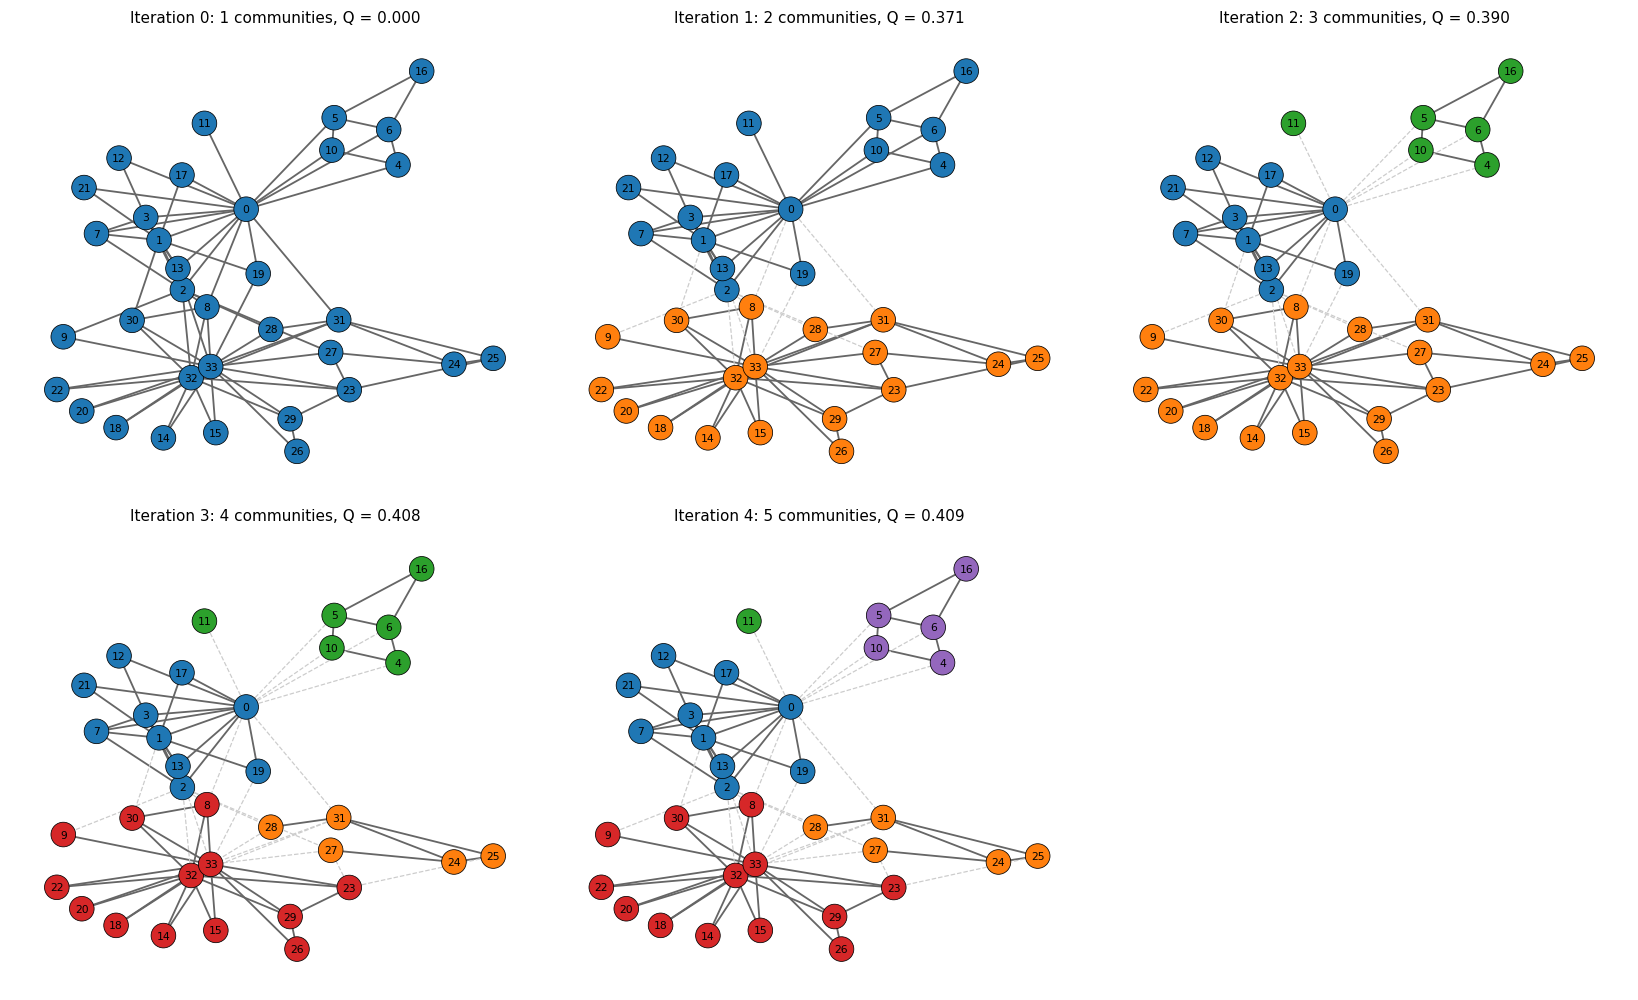

In [9]:
pos = nx.spring_layout(G, seed=42)                    # computed ONCE -> identical positions in every plot
palette = plt.cm.tab10.colors

def draw_partition(ax, labels, title):
    cross = [(u, v) for u, v in G.edges() if labels[u] != labels[v]]
    within = [(u, v) for u, v in G.edges() if labels[u] == labels[v]]
    nx.draw_networkx_edges(G, pos, edgelist=within, ax=ax, width=1.2, edge_color="0.4")
    nx.draw_networkx_edges(G, pos, edgelist=cross, ax=ax, width=0.8, edge_color="0.8", style="dashed")
    colors = [palette[labels[i] % len(palette)] for i in nodes]
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=260, edgecolors="k", linewidths=0.5)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
    ax.set_title(title, fontsize=10); ax.axis("off")

ncols = 3
nrows = int(np.ceil(len(history) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.6 * nrows))
for ax in axes.ravel(): ax.axis("off")
for ax, h in zip(axes.ravel(), history):
    num = len(set(h["labels"]))
    draw_partition(ax, h["labels"], f"Iteration {h['iteration']}: {num} communities, Q = {h['Q']:.3f}")
plt.tight_layout()
plt.savefig("assets/partitions_by_iteration.png", bbox_inches="tight")
plt.show()

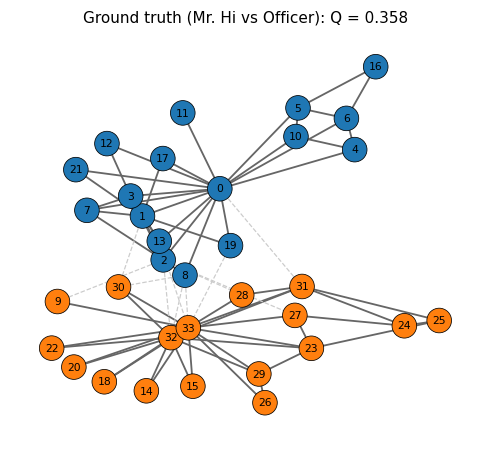

In [10]:
# Bonus: the real-world split drawn the same way, for comparison with Iteration 1
fig, ax = plt.subplots(figsize=(5.5, 4.8))
draw_partition(ax, truth, f"Ground truth (Mr. Hi vs Officer): Q = {modularity_from_labels(B, truth, m):.3f}")
plt.savefig("assets/ground_truth.png", bbox_inches="tight")
plt.show()

## 6. Node metrics after every split

The four metrics (all from NetworkX): `degree_centrality`, `betweenness_centrality`, `closeness_centrality`, `clustering`.

**Design choice that matters.** If we computed these on the *original* graph `G`, nothing would change from split to split (the graph itself never changes — only our labels do). To see how the *community structure* influences the metrics, after each split we compute them on the **within-community graph** `H_t`: the same 34 nodes, but keeping **only edges whose two endpoints share a community** (i.e., the union of the induced community subgraphs). Cross-community edges are "cut".

So iteration 0 = the full graph, and later iterations show each node's standing *inside its own community*.

Technical notes:
* Degree centrality still divides by `n−1 = 33`, so it can only go down as edges are cut.
* After cuts `H_t` is disconnected; NetworkX's `closeness_centrality` handles this by scaling by the size of the reachable component (Wasserman–Faust), and betweenness counts only paths that exist.
* A node isolated in its community (singleton) gets 0 for all four metrics.

In [11]:
def within_community_graph(G, labels):
    """Same nodes as G, but keep only the edges whose endpoints share a community label."""
    H = nx.Graph()
    H.add_nodes_from(G.nodes())
    H.add_edges_from((u, v) for u, v in G.edges() if labels[u] == labels[v])
    return H

metric_funcs = {
    "Degree centrality":      nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality":   nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

# metrics[name][iteration] = {node: value}      (dictionary keyed by iteration, as the handout asks)
metrics = {name: {} for name in metric_funcs}
for h in history:
    H = within_community_graph(G, h["labels"])
    for name, f in metric_funcs.items():
        metrics[name][h["iteration"]] = f(H)

# Sanity check: at iteration 0 the metrics must equal those of the original graph
assert all(abs(metrics["Degree centrality"][0][i] - nx.degree_centrality(G)[i]) < 1e-12 for i in nodes)
assert all(abs(metrics["Betweenness centrality"][0][i] - nx.betweenness_centrality(G)[i]) < 1e-12 for i in nodes)
print("Iteration-0 metrics match the full graph.  Metrics computed for", len(history), "iterations.")

# Quick look: top 5 nodes by betweenness at the first and last iteration
last = history[-1]["iteration"]
for it in (0, last):
    top = sorted(metrics["Betweenness centrality"][it].items(), key=lambda t: -t[1])[:5]
    print(f"Top-5 betweenness at iteration {it}:", [(i, round(v, 3)) for i, v in top])

Iteration-0 metrics match the full graph.  Metrics computed for 5 iterations.
Top-5 betweenness at iteration 0: [(0, 0.438), (33, 0.304), (32, 0.145), (2, 0.144), (31, 0.138)]
Top-5 betweenness at iteration 4: [(33, 0.068), (32, 0.032), (0, 0.024), (1, 0.015), (24, 0.006)]


### Plotting the evolution
Each metric gets two views:
* **Line plot** — one line per node across iterations. With 34 nodes this is crowded, so the 5 nodes with the highest *average* value are **highlighted and labelled**, and the rest are faint grey.
* **Heatmap** — all 34 nodes (rows) × iterations (columns), for reading every node at once.

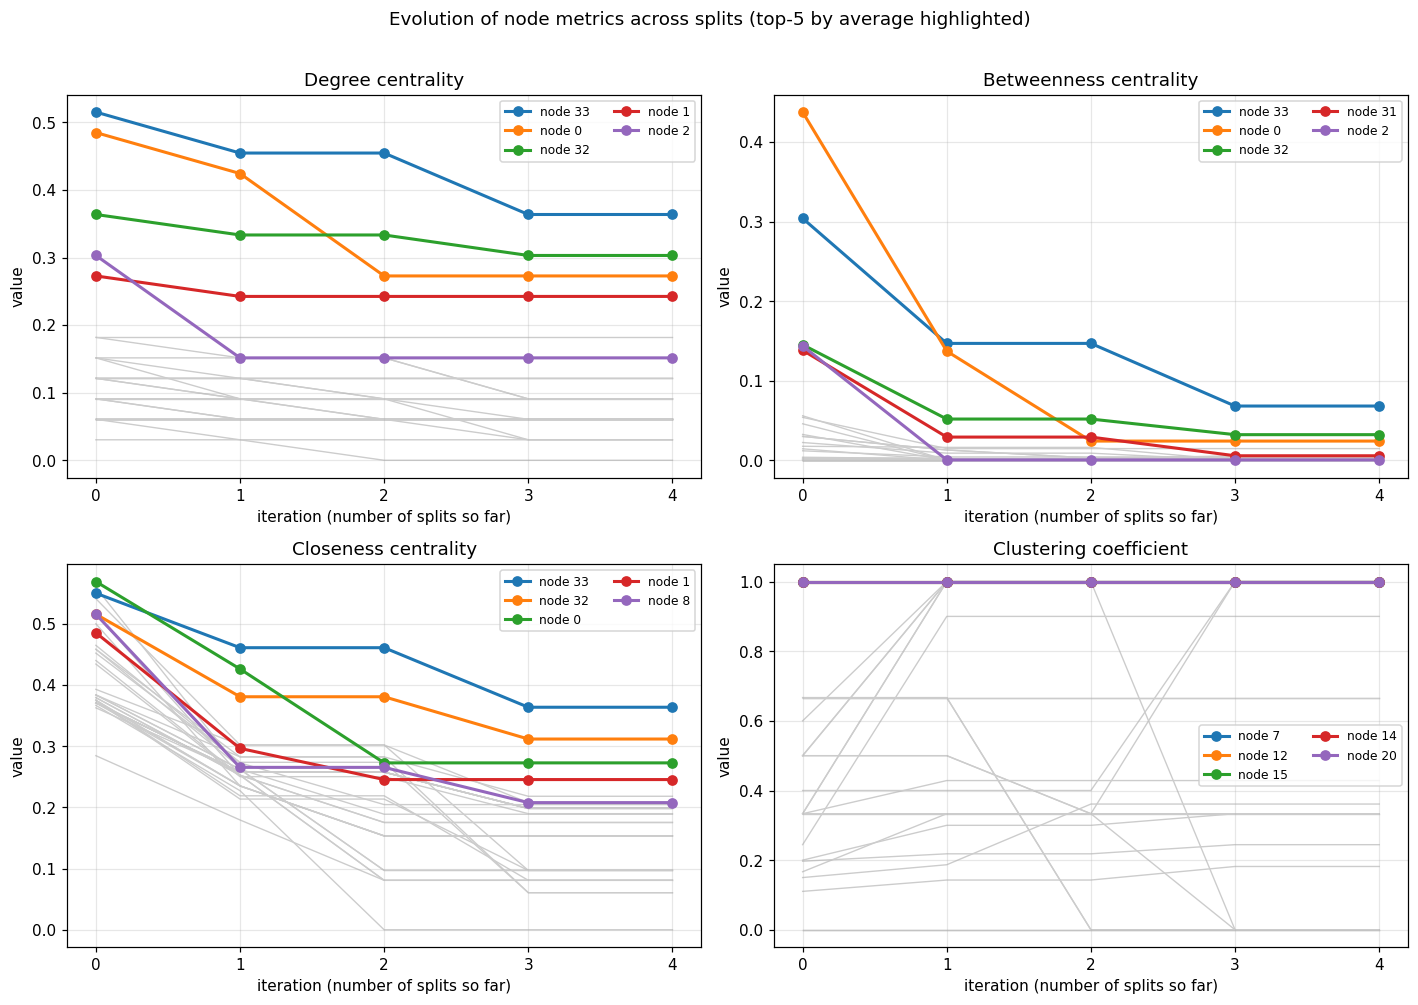

In [12]:
iters = [h["iteration"] for h in history]

def metric_matrix(name):
    """rows = nodes 0..33, columns = iterations"""
    return np.array([[metrics[name][it][i] for it in iters] for i in nodes])

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, name in zip(axes.ravel(), metric_funcs):
    M = metric_matrix(name)
    top = np.argsort(-M.mean(axis=1))[:5]                     # 5 nodes with the highest average value
    for i in nodes:
        if i not in top:
            ax.plot(iters, M[i], color="0.8", lw=0.9, zorder=1)
    for rank, i in enumerate(top):
        ax.plot(iters, M[i], marker="o", lw=2, color=palette[rank], label=f"node {i}", zorder=3)
    ax.set_title(name); ax.set_xlabel("iteration (number of splits so far)"); ax.set_ylabel("value")
    ax.set_xticks(iters); ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
plt.suptitle("Evolution of node metrics across splits (top-5 by average highlighted)", y=1.01)
plt.tight_layout()
plt.savefig("assets/metric_evolution_lines.png", bbox_inches="tight")
plt.show()

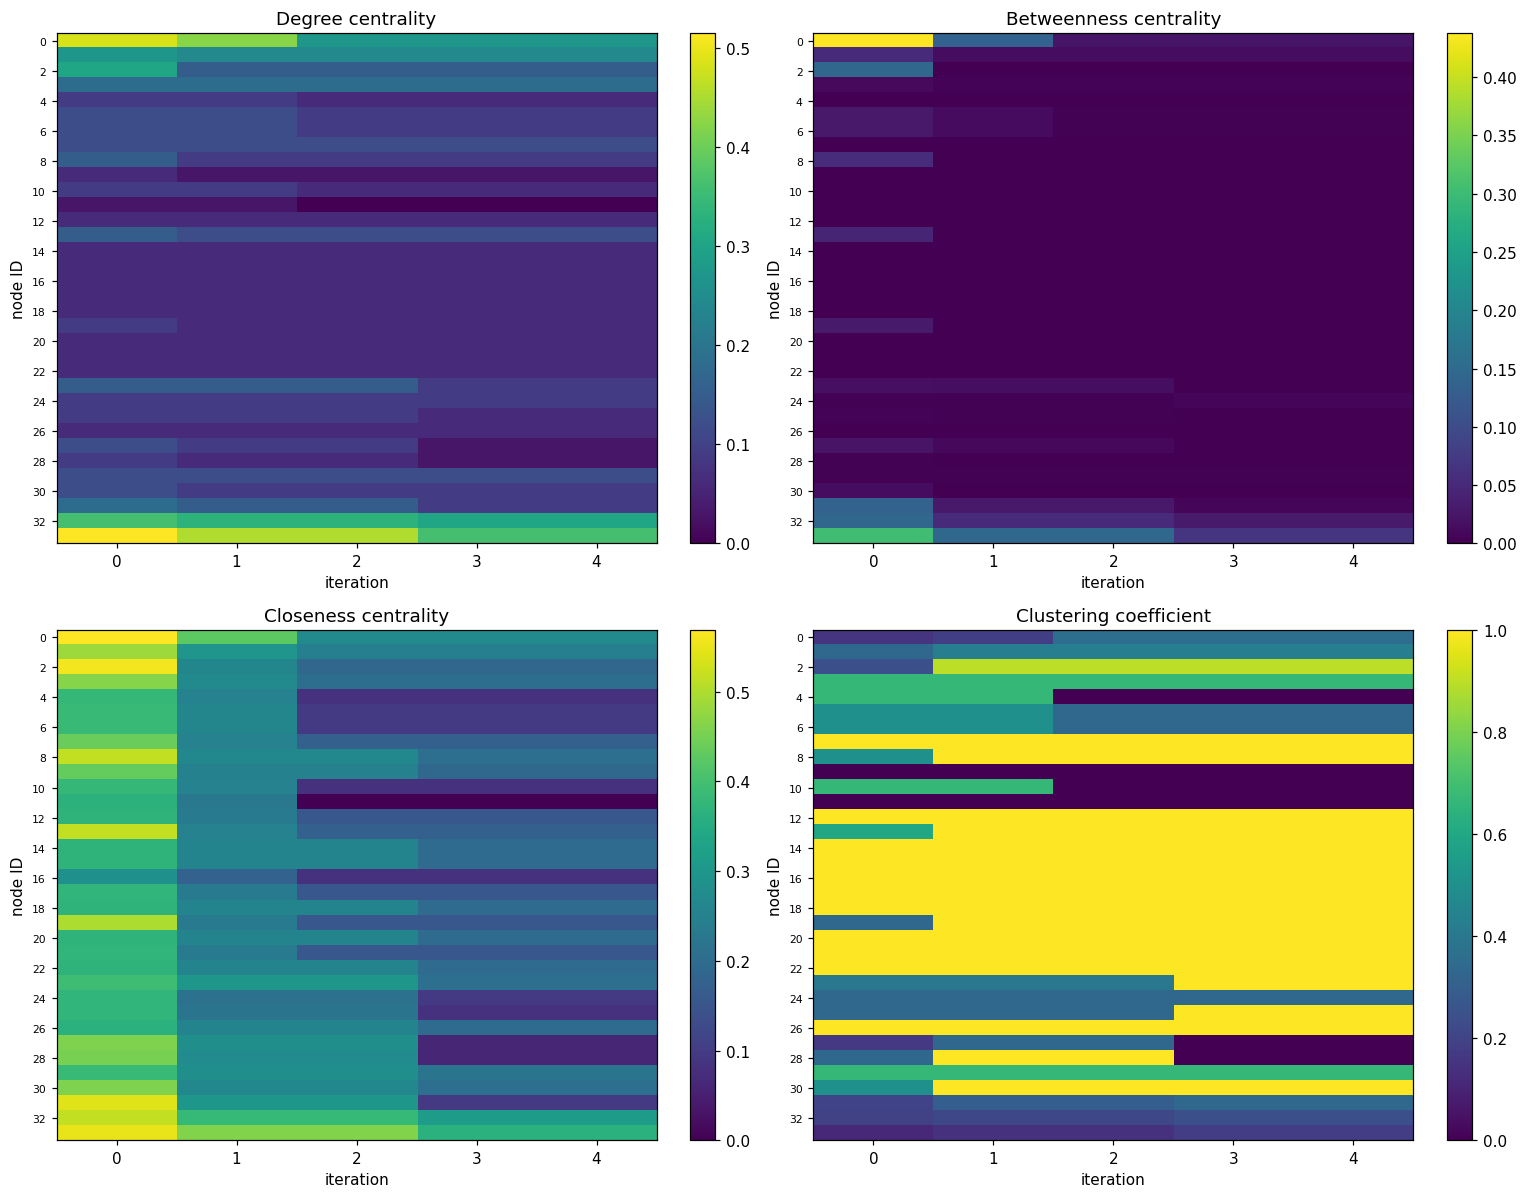

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, name in zip(axes.ravel(), metric_funcs):
    M = metric_matrix(name)
    im = ax.imshow(M, aspect="auto", cmap="viridis")
    ax.set_title(name); ax.set_xlabel("iteration"); ax.set_ylabel("node ID")
    ax.set_xticks(range(len(iters))); ax.set_xticklabels(iters)
    ax.set_yticks(range(0, n, 2)); ax.set_yticklabels(range(0, n, 2), fontsize=7)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig("assets/metric_evolution_heatmaps.png", bbox_inches="tight")
plt.show()

### Evidence for the discussion
Which nodes are *consistently* central? For each metric and iteration we rank all nodes (1 = most central) and then average that rank across iterations. A low average rank = consistently near the top.

In [14]:
def mean_rank_table(name, top=6):
    M = metric_matrix(name)                                              # nodes x iterations
    ranks = (-M).argsort(axis=0).argsort(axis=0) + 1                     # rank per column (1 = highest)
    avg = ranks.mean(axis=1)
    order = np.argsort(avg)[:top]
    return [(int(i), round(float(avg[i]), 2)) for i in order]

for name in metric_funcs:
    print(f"{name:24s} (node, mean rank):", mean_rank_table(name))

# Which community is each hub in at the end?
print()
for hub in (0, 33, 32, 2):
    print(f"Node {hub:2d}: final community {final_labels[hub]}, degree {int(k[hub])}")

Degree centrality        (node, mean rank): [(33, 1.0), (32, 2.4), (0, 2.6), (1, 4.2), (3, 5.2), (2, 6.4)]
Betweenness centrality   (node, mean rank): [(33, 1.2), (32, 2.4), (0, 2.6), (31, 4.8), (1, 5.4), (5, 8.6)]
Closeness centrality     (node, mean rank): [(33, 1.4), (32, 3.2), (0, 3.4), (23, 7.6), (29, 7.8), (1, 8.2)]
Clustering coefficient   (node, mean rank): [(7, 1.0), (14, 3.2), (15, 3.8), (12, 4.4), (13, 4.8), (26, 8.4)]

Node  0: final community 0, degree 16
Node 33: final community 3, degree 17
Node 32: final community 3, degree 12
Node  2: final community 0, degree 10


## 7. Extension — the corrected (generalised) modularity matrix
The handout restricts `B` to a block `B^(C)`. In Newman's paper the exact modularity gain of splitting a group `g` uses the **generalised** matrix

$$B^{(g)}_{ij} = B_{ij} - \delta_{ij}\sum_{l\in g} B_{il},$$

which subtracts each row's sum on the diagonal (so, like the full `B`, every row sums to zero). We implemented this as `use_correction=True`. Let us compare both versions as a robustness check.

In [15]:
lab_c, hist_c = recursive_partition(B, m, use_correction=True)
print(f"{'':28s}{'#communities':>13s}{'final Q':>9s}")
print(f"{'Handout (plain block B[C,C])':28s}{len(set(final_labels)):>13d}{history[-1]['Q']:>9.4f}")
print(f"{'Newman generalised matrix':28s}{len(set(lab_c)):>13d}{hist_c[-1]['Q']:>9.4f}")
print()
print("Q after each split, handout   :", [round(h['Q'], 4) for h in history])
print("Q after each split, generalised:", [round(h['Q'], 4) for h in hist_c])

                             #communities  final Q
Handout (plain block B[C,C])            5   0.4094
Newman generalised matrix               5   0.3776

Q after each split, handout   : [0.0, 0.3715, 0.3898, 0.4081, 0.4094]
Q after each split, generalised: [0.0, 0.3715, 0.3727, 0.3934, 0.3776]


**Observation:** both versions agree on the first split (the one that matches the real club division). They can differ afterwards, because the plain block `B[C,C]` does **not** have a guaranteed zero eigenvalue and ignores the fact that nodes in `C` also have edges leaving `C`, whereas the generalised matrix accounts for it. A rounded (±1) split can also fail to improve `Q` even when `λ₁ > 0` (the eigenvalue bound is for the *relaxed* problem) — watch for any step where `Q` goes **down** in the lists above.

## 8. Discussion

### 8.1 Does spectral modularity recover the real split?
The modularity matrix passes all sanity checks (symmetric, `B·1 = 0`, Q(trivial) = 0, real eigenvalues), and its largest eigenvalue is λ₁ = 4.977 > 0, so the network can be split. Splitting by the sign of the leading eigenvector gives a 16 / 18 bipartition that agrees with the real club split for 33 of 34 members (97.1%). The only misplaced member is node 8. Node 8 has 5 friends: two in Mr. Hi's group (0 and 2) and three on the administrator's side (30, 32, 33). A method that sees only the graph has good reason to put it with the majority of its friends, even though the real split put it with Mr. Hi.

The split found by the algorithm has a *higher* modularity (Q = 0.3715) than the real-world split (Q = 0.3582), which is expected since the algorithm optimises Q while real people follow loyalties. Both are well below the theoretical ceiling for two groups, n·λ₁/(4m) ≈ 0.54 (from the Rayleigh–Ritz bound).

### 8.2 What recursive bisection adds
| Iteration | Communities | λ₁ of split group | Q | Gain in Q |
|---|---|---|---|---|
| 0 | 1 | – | 0.000 | – |
| 1 | 2 | 4.977 | 0.3715 | +0.3715 |
| 2 | 3 | 2.944 | 0.3898 | +0.0183 |
| 3 | 4 | 2.504 | 0.4081 | +0.0183 |
| 4 | 5 | 2.148 | 0.4094 | +0.0013 |

Q increases at every split but with diminishing returns: the first split does almost all the work, the next two add about 0.018 each, and the last adds only 0.0013. The final partition has 5 communities (Q = 0.4094) and refines the two factions rather than contradicting them. Mr. Hi's side splits into {0,1,2,3,7,12,13,17,19,21}, {4,5,6,10,16} and the singleton {11}. The administrator's side splits into {8,9,14,15,18,20,22,23,26,29,30,32,33} and {24,25,27,28,31}. The last split only separates node 11 (a member whose single friend is node 0) as a singleton. That gain is tiny, so it is arguably an artefact of the simplified stopping rule, and it echoes the "isolate one vertex" problem that motivated modularity.

### 8.3 Which nodes remain central across splits?
Averaging each node's rank over all iterations (1 = most central), node **33** is the most central for degree (mean rank 1.0), betweenness (1.2) and closeness (1.4). Nodes **32** and **0** follow (ranks about 2.4–3.4 across the three metrics). These are the highest-degree members (node 33 has degree 17 and node 0 degree 16) and each is the hub of one faction, so they keep most of their edges and their short routes to others after the cuts. Node 0 starts as the top broker (betweenness 0.438 vs 0.304 for node 33) but is overtaken by node 33 after the first splits: node 0's betweenness drops from 0.438 to 0.024, while node 33's only drops to 0.068. Many shortest paths through node 0 were the only way to reach members such as 11 and {4,5,6,10,16}, who hang off node 0, and those paths disappear once they are separated into their own communities.

Clustering behaves differently. The "most consistent" nodes by clustering (7, 14, 15, 12, 20) are not hubs. They are low-degree members whose neighbours are all connected to each other (clustering = 1.0 at every iteration). Many nodes tie at 1.0, so the mean-rank ordering for clustering is not very informative.

### 8.4 How community structure influences each metric
Metrics were computed after each split on the graph with cross-community edges removed, so changes reflect how each node sits *inside its own community*.
* **Degree centrality** can only fall, because cutting edges removes neighbours. Hubs keep most of theirs (node 33: 0.515 → 0.364; node 32: 0.364 → 0.303), while node 0 loses 7 of its 16 friends (0.485 → 0.273) and node 2 drops from 0.303 to 0.152.
* **Betweenness** collapses for almost every node (the average falls from about 0.044 to 0.005; node 2 goes from 0.144 to 0). Betweenness counts bridging between groups, and a split removes the bridges.
* **Closeness** falls for all nodes (the average drops from about 0.43 to 0.17), because after the cuts a node can only reach members of its own community. Because NetworkX scales closeness by the size of the reachable part, a node in a small community scores low even if it is well connected there. Node 11 is isolated from iteration 2 onwards and drops to 0.
* **Clustering** mostly *rises*. Cross-community links are usually the edges that close few triangles, so removing them leaves the tight local cliques: node 8 goes from 0.5 to 1.0 and node 2 from 0.24 to 0.9. Nodes whose remaining neighbours are not linked to each other (e.g. 4, 10, 28 at later iterations) fall to 0.

Taken together, splitting turns one connected network into several smaller, denser ones. Nodes become less central in the global sense (lower degree, betweenness and closeness) but more embedded locally (higher clustering).

### 8.5 Handout rule vs Newman's generalised matrix
Both versions make the same first split (Q = 0.3715) and end with 5 communities, but the handout's plain block `B[C,C]` ends at Q = 0.4094 while Newman's generalised matrix ends at 0.3776. In the generalised run, Q goes *down* at the last split (0.3934 → 0.3776) even though λ₁ > 0 (it was only 0.06). The eigenvalue bound applies to the relaxed problem, and rounding the eigenvector to ±1 can lose the gain. Checking that ΔQ > 0 before accepting a split would prevent this.

### 8.6 Limitations
* Computing metrics on the within-community graph is my design choice; computing them on the original graph would give constant values.
* The handout's stopping rule uses the plain block `B[C,C]`, a simplification of the exact gain, which can accept splits with very small benefit (such as isolating node 11).
* Eigenvector rounding can misplace borderline nodes (node 8), and the method only finds a good partition, not guaranteed to be the global optimum of Q.